# Manual Verification of the GENIE Expected Cross Section -- $\delta p_T$

**Goal:** independently cross-check GUNDAM's "expected GENIE" $d\sigma/d\delta p_T$ against a
from-scratch calculation built directly from the GUNDAM input file's truth-level `signal` tree,
using only the flux and number-of-targets normalization constants (no NUISANCE FlatTree machinery,
no GUNDAM fit/CalcXsec output). If the two agree, that validates the flux and target normalization
independently of the NUISANCE-based pipeline used elsewhere in the analysis. If they don't, the
disagreement is a real bug to chase.

**Inputs:**
- Signal tree: `events/full/signal` in
  `ICARUS_CC0pi_Selection/data/icarus_numi_numu_mc_onbeam_offbeam_syst_gundam.root`
- Binning: `gundam-icarus/configs/binnings/binning_true_dpT.txt` (the binning GUNDAM's own
  `Template Parameter true_dpT_lp_genie` / CalcXsec output actually uses)
- Flux and number of targets: `gundam-icarus/configs/Configs_FitSampleSet/fitSamples_true_dpT.yaml`
- Comparison target: the GENIE NUISANCE FlatTree files in `data/Generators/GENIE/{fhc_Nu14,fhc_Nu-14}`,
  via the existing `overlay_genie_nuisance_xsec` (self-normalized through NUISANCE's own
  `fScaleFactor`, entirely independent of the flux/N_targets constants used in Part 1 below)


In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec

import numpy as np
import uproot
import matplotlib.pyplot as plt

GUNDAM_ROOT = "/sessions/rcw-01vytdbsbz3jtgxgc9y3f38u/mnt/ICARUS_CC0pi_Selection/data/icarus_numi_numu_mc_onbeam_offbeam_syst_gundam.root"
NUISANCE_DIR_NUMU = "/sessions/rcw-01vytdbsbz3jtgxgc9y3f38u/mnt/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14"
NUISANCE_DIR_NUMUBAR = "/sessions/rcw-01vytdbsbz3jtgxgc9y3f38u/mnt/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14"


## Part 1 -- Manual calculation from the signal tree

**Binning** (`configs/binnings/binning_true_dpT.txt`, in MeV/c -- this is the ACTUAL binning
GUNDAM's fit and `CalcXsec` output use, NOT the `[0, 80, 160, 240, 320, 520, 800]` binning defined
separately in `dpT.toml`'s `true_dpT_smearing` variable, which is a different, unrelated diagnostic
binning used for smearing-matrix plots):

$$[0,\ 135,\ 246,\ 352,\ 465,\ 598,\ 800]\ \text{MeV/c},\quad \text{plus overflow } [800, \infty)$$

**Normalization** (`Configs_FitSampleSet/fitSamples_true_dpT.yaml`):
- Flux $\Phi = 5.191500\times10^{11}$ (numu+numubar)/cm$^2$
- Number of targets $N_{\rm targets} = 4.721444\times10^{30}$

**Signal definition:** the `category` branch in `events/full/signal` takes only the values
`{0, 1, 2}` in this tree (QE, 2p2h, pion-absorption -- the truth-level 1$\mu$N$p$0$\pi$ signal
subcategories), confirmed below by checking its distribution directly rather than assuming the
default `category_cuts=[0,1,3,4]` in `overlay_manual_cross_section` (that default is stale for this
tree -- categories 3 and 4 don't exist here, so it would silently drop the pion-absorption channel).

**Formula, explicit, per bin $i$:**
$$\sigma_i = \frac{\sum_{\text{events in bin }i,\ \text{cat}\in\{0,1,2\}} w_{\rm ppfx\_cv}}{\Phi \cdot N_{\rm targets} \cdot \Delta(\delta p_T)_i}$$


In [2]:
FLUX = 5.191500e+11       # (numu+numubar)/cm^2 -- fitSamples_true_dpT.yaml
N_TARGETS = 4.721444e+30 # fitSamples_true_dpT.yaml
CATEGORY_CUTS = [0, 1, 2] # QE, 2p2h, pi-abs -- verified below, NOT the function default [0,1,3,4]
BINS_MEV = [(0,135),(135,246),(246,352),(352,465),(465,598),(598,800),(800,99999)]

# Sanity check: confirm which category values actually appear in this tree
tree = uproot.open(GUNDAM_ROOT)["events/full/signal"]
cat_vals = tree["category"].array(library="np")
print("category values present in events/full/signal:", sorted(set(cat_vals.tolist())))
print("-> overlay_manual_cross_section's own default category_cuts=[0,1,3,4] would be WRONG here")
print("   (it would silently keep only cat 0 and 1, dropping the pi-abs channel entirely)\n")

fig1, ax1 = plt.subplots(figsize=(6,5))
fig1, ax1, xsec_manual = overlay_manual_cross_section(
    fig1, ax1,
    root_file_path=GUNDAM_ROOT,
    bins_mev=BINS_MEV,
    n_targets=N_TARGETS,
    flux=FLUX,
    signal_tree_path="events/full/signal",
    variable_name="true_dpT_lp_genie",
    category_cuts=CATEGORY_CUTS,
    color='red',
    label='Manual (signal tree, flux x targets)',
    scaling_power_of_10=1e37,
    energy_conversion=True,
)
plt.close(fig1)  # figure re-drawn combined with the GENIE overlay in Part 2


category values present in events/full/signal: [0, 1, 2]
-> overlay_manual_cross_section's own default category_cuts=[0,1,3,4] would be WRONG here
   (it would silently keep only cat 0 and 1, dropping the pi-abs channel entirely)


Signal Events and Cross-Section per True Bin
Bin Range (MeV/c)         N_Signal     Bin Width (MeV)    σ (x10^-37 cm²/GeV)
------------------------------------------------------------------------------------------
     0 - 135    MeV/c    30036        135                8.568524e-01
   135 - 246    MeV/c    29793        111                1.033721e+00
   246 - 352    MeV/c    14633        106                5.322510e-01
   352 - 465    MeV/c    12004        113                4.102019e-01
   465 - 598    MeV/c    10513        133                3.057068e-01
   598 - 800    MeV/c    9620         202                1.848052e-01
   800 - 99999  MeV/c    5870         ∞                  N/A (infinite bin)
----------------------------------------------------------

## Part 2 -- Compare to the GENIE NUISANCE FlatTree files, on the SAME (correct) bin edges

`overlay_genie_nuisance_xsec` reads `output_GENIE_*.nuisflat.root` and self-normalizes through
NUISANCE's own `fScaleFactor` branch (`FinalWeight = InputWeight * fScaleFactor`) -- a completely
independent normalization pathway from the flux/N_targets calculation in Part 1. Agreement between
the two is a genuine cross-check of both the flux prediction and the number-of-targets estimate.

The bin edges must be passed in **GeV/c** here (the `ICARUS_1muNp0pi_deltaPT` branch in the nuisflat
files is stored in GeV/c) -- i.e. `binning_true_dpT.txt`'s MeV edges divided by 1000:
`[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8]`.



GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.694343e-01
  0.1350 – 0.2460           1.048886e+00
  0.2460 – 0.3520           5.364157e-01
  0.3520 – 0.4650           4.182228e-01
  0.4650 – 0.5980           3.101735e-01
  0.5980 – 0.8000           1.838615e-01

Signal Events and Cross-Section per True Bin
Bin Range (MeV/c)         N_Signal     Bin Width (MeV)    σ (x10^-37 cm²/GeV)
------------------------------------------------------------------------------------------
     0 - 135    MeV/c    30036        135                8.568524e-01
   135 - 246    MeV/c    29793        111                1.033721e+00
   246 - 352    MeV/c    14633        106                5.322510e-01
   352 - 465    MeV/c    12004        113                4.102019e-01
   465 - 598    MeV/c    10513        133                3.057068e-01
   598 - 800   

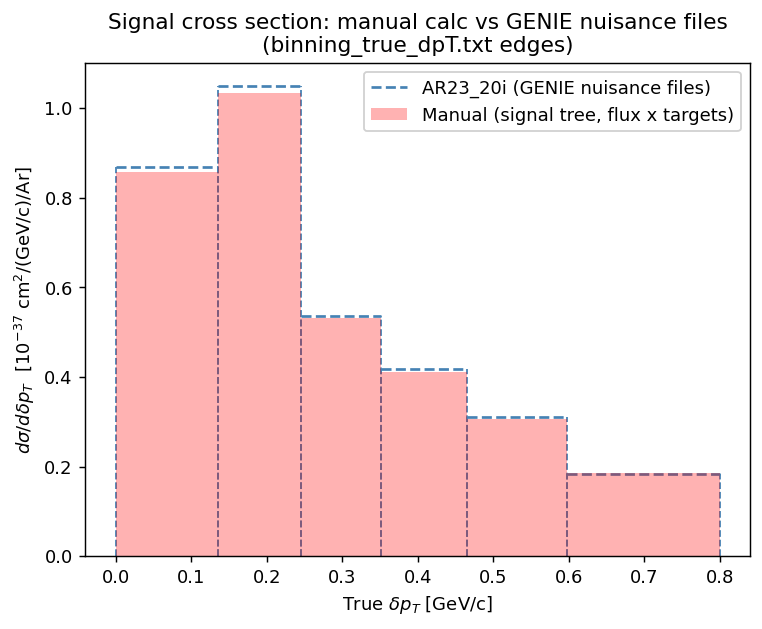

In [3]:
CORRECT_EDGES_GEV = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8]

fig, ax = plt.subplots(figsize=(6,5))
fig, ax, xsec_genie, _ = overlay_genie_nuisance_xsec(
    fig, ax,
    nuisance_file_dir=NUISANCE_DIR_NUMU,
    nuisance_file_dir_numubar=NUISANCE_DIR_NUMUBAR,
    bin_edges=CORRECT_EDGES_GEV,
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='AR23_20i (GENIE nuisance files)',
    color='steelblue',
)
fig, ax, xsec_manual = overlay_manual_cross_section(
    fig, ax,
    root_file_path=GUNDAM_ROOT,
    bins_mev=BINS_MEV,
    n_targets=N_TARGETS,
    flux=FLUX,
    signal_tree_path="events/full/signal",
    variable_name="true_dpT_lp_genie",
    category_cuts=CATEGORY_CUTS,
    color='red',
    label='Manual (signal tree, flux x targets)',
    scaling_power_of_10=1e37,
    energy_conversion=True,
)
ax.set_xlabel(r'True $\delta p_T$ [GeV/c]')
ax.set_ylabel(r'$d\sigma/d\delta p_T$  [$10^{-37}$ cm$^2$/(GeV/c)/Ar]')
ax.set_title("Signal cross section: manual calc vs GENIE nuisance files\n(binning_true_dpT.txt edges)")
fig.tight_layout()
plt.show()


### Explicit bin-by-bin ratio (manual / GENIE-nuisance-file)

In [4]:
header = "{:<20}{:>14}{:>20}{:>22}".format("Bin [GeV/c]", "Manual", "GENIE (nuisance)", "Ratio manual/genie")
print(header)
for i, (lo, hi) in enumerate(zip(CORRECT_EDGES_GEV[:-1], CORRECT_EDGES_GEV[1:])):
    ratio = xsec_manual[i] / xsec_genie[i]
    bin_str = "{:.3f}-{:.3f}".format(lo, hi)
    print("{:<20}{:>14.4f}{:>20.4f}{:>22.4f}".format(bin_str, xsec_manual[i], xsec_genie[i], ratio))


Bin [GeV/c]                 Manual    GENIE (nuisance)    Ratio manual/genie
0.000-0.135                 0.8569              0.8694                0.9855
0.135-0.246                 1.0337              1.0489                0.9855
0.246-0.352                 0.5323              0.5364                0.9922
0.352-0.465                 0.4102              0.4182                0.9808
0.465-0.598                 0.3057              0.3102                0.9856
0.598-0.800                 0.1848              0.1839                1.0051


## Part 3 -- Why the earlier LQCD / MINERvA fake-data closure looked broken

The `FakeData_LQCD_Containment_Studies.ipynb` / `FakeData_MINERvA_Containment_Studies.ipynb`
notebooks' "Overlay 1" cell computed the GENIE nominal cross section with
`bin_edges=[0.0, 0.08, 0.16, 0.24, 0.32, 0.52, 0.8]`. That array is **not**
`binning_true_dpT.txt` -- it is `dpT.toml`'s separate `[variables.true_dpT_smearing]` /
`custom_bins`, a diagnostic binning used elsewhere for smearing-matrix plots, that happens to also
run from 0 to 800 MeV/c in 6 bins. Meanwhile `xsec_extracted` in those notebooks comes from
GUNDAM's own `CalcXsec` output (`calcXsec/histograms/True_dpT_XS_TH1D`), whose 6 bins are the real
`binning_true_dpT.txt` edges. Comparing the two arrays index-by-index was comparing six *different*
true-$\delta p_T$ ranges to each other, not the same six ranges under two models -- enough on its
own to produce a spurious, wrong-shaped "non-closure," independent of any real fit-degeneracy
physics.

Recomputing the GENIE nominal on the old, mismatched edges for reference:


In [5]:
OLD_WRONG_EDGES_GEV = [0.0, 0.08, 0.16, 0.24, 0.32, 0.52, 0.8]  # dpT.toml true_dpT_smearing custom_bins / 1000

fig3, ax3 = plt.subplots(figsize=(5,4))
fig3, ax3, xsec_wrong, _ = overlay_genie_nuisance_xsec(
    fig3, ax3,
    nuisance_file_dir=NUISANCE_DIR_NUMU,
    nuisance_file_dir_numubar=NUISANCE_DIR_NUMUBAR,
    bin_edges=OLD_WRONG_EDGES_GEV,
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='AR23_20i (old/wrong edges)',
    color='gray',
)
plt.close(fig3)

print("\nSide-by-side (NOT the same true-dpT ranges -- shown only to make the mismatch concrete):")
header2 = "{:<12}{:<24}{:>16}{:<24}{:>14}".format("Bin index", "Correct edges [GeV]", "xsec (correct)", "Old/wrong edges [GeV]", "xsec (wrong)")
print(header2)
for i in range(6):
    lo_c, hi_c = CORRECT_EDGES_GEV[i], CORRECT_EDGES_GEV[i+1]
    lo_w, hi_w = OLD_WRONG_EDGES_GEV[i], OLD_WRONG_EDGES_GEV[i+1]
    correct_str = "{:.3f}-{:.3f}".format(lo_c, hi_c)
    wrong_str = "{:.3f}-{:.3f}".format(lo_w, hi_w)
    print("{:<12}{:<24}{:>16.4f}{:<24}{:>14.4f}".format(i, correct_str, xsec_genie[i], wrong_str, xsec_wrong[i]))



GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.0800           6.650366e-01
  0.0800 – 0.1600           1.177104e+00
  0.1600 – 0.2400           1.021996e+00
  0.2400 – 0.3200           5.790883e-01
  0.3200 – 0.5200           4.070170e-01
  0.5200 – 0.8000           2.123250e-01

Side-by-side (NOT the same true-dpT ranges -- shown only to make the mismatch concrete):
Bin index   Correct edges [GeV]       xsec (correct)Old/wrong edges [GeV]     xsec (wrong)
0           0.000-0.135                       0.86940.000-0.080                     0.6650
1           0.135-0.246                       1.04890.080-0.160                     1.1771
2           0.246-0.352                       0.53640.160-0.240                     1.0220
3           0.352-0.465                       0.41820.240-0.320                     0.5791
4           0.465-0.598            

## Part 4 -- Effect of each fake-data reweighting, applied directly to the signal tree

For every fake-data study performed so far, its exact `nominalWeightFormula` (from the
corresponding `dataSetListConfig_FakeData_*.yaml`, quoted verbatim below in each subsection) is
applied directly to the truth-level `events/full/signal` tree in place of the plain
`ppfx_cv_weight`, and the resulting cross section is recomputed with the *identical* formula and
binning as Part 1. That reweighted cross section is then compared directly to
**`xsec_genie`, the GENIE NUISANCE FlatTree cross section from Part 2** -- i.e. the actual
external "GENIE nominal" reference, not the internal Part-1 manual recomputation -- per your
request to compare against "the genie nominal cross section (without fake data criteria)".

For reference, row 0 of every table below is the **undistorted** signal-tree recomputation
(`ppfx_cv_weight` alone, no fake-data reweighting), so the small ~1-2% manual-vs-GENIE baseline
offset already documented in Part 1 is visible on its own line, separate from each study's
reweighting effect. Each subsection also includes a bar-overlay plot of the GENIE nominal vs the
fake-data-reweighted cross section, on the same axes, so the effect is visible directly and not
just numerically.

**Formula reused from Part 1** (`overlay_manual_cross_section`'s internal calculation, reproduced
here as a plain function so an arbitrary per-event weight array -- not just the fixed
`ppfx_cv_weight` column -- can be plugged in for each study):
$$\sigma_i = \frac{\sum_{\text{events in bin }i,\ \text{cat}\in\{0,1,2\}} w_i}{\Phi \cdot N_{\rm targets} \cdot \Delta(\delta p_T)_i} \times 10^{3}\times10^{37}$$
(the $10^3$ converts the MeV bin width to the GeV-width convention used by `scaling_power_of_10=1e37`,
identical to the Part-1 utility -- not a new choice.)


In [6]:
def compute_signal_xsec(dpt_mev, weight, category, category_cuts, bins_mev, n_targets, flux, scaling_power_of_10=1e37):
    """Identical arithmetic to overlay_manual_cross_section (Part 1), generalized to accept
    an arbitrary per-event weight array instead of a fixed ppfx_cv_weight column."""
    sig_mask = np.zeros(len(category), dtype=bool)
    for c in category_cuts:
        sig_mask = sig_mask | (category == c)
    dpt_sig = dpt_mev[sig_mask]
    w_sig = weight[sig_mask]
    xsecs = []
    for lo, hi in bins_mev:
        if hi >= 99999:
            continue  # overflow bin excluded, same as Part 1
        bin_mask = (dpt_sig >= lo) & (dpt_sig < hi)
        w_sum = float(np.sum(w_sig[bin_mask]))
        bin_width_mev = hi - lo
        xsec = 1e3 * scaling_power_of_10 * w_sum / (n_targets * flux * bin_width_mev)
        xsecs.append(xsec)
    return np.array(xsecs)

def print_deviation_table(edges_gev, xsec_ref, xsec_study, ref_label, study_label):
    header = "{:<20}{:>18}{:>22}{:>12}{:>14}".format("Bin [GeV/c]", ref_label, study_label, "Ratio", "Dev [%]")
    print(header)
    for i, (lo, hi) in enumerate(zip(edges_gev[:-1], edges_gev[1:])):
        ratio = xsec_study[i] / xsec_ref[i]
        dev_pct = (ratio - 1.0) * 100.0
        bin_str = "{:.3f}-{:.3f}".format(lo, hi)
        print("{:<20}{:>18.4f}{:>22.4f}{:>12.4f}{:>14.2f}".format(bin_str, xsec_ref[i], xsec_study[i], ratio, dev_pct))

def plot_comparison(edges_gev, xsec_ref, xsec_study, ref_label, study_label, title, study_color):
    """Bar-overlay plot: GENIE nominal vs the fake-data-reweighted signal-tree cross section,
    same style as the Part 2 overlay (alpha-blended bars on shared axes)."""
    bin_centers = [(edges_gev[i] + edges_gev[i+1]) / 2.0 for i in range(len(edges_gev) - 1)]
    bin_widths = [edges_gev[i+1] - edges_gev[i] for i in range(len(edges_gev) - 1)]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.bar(bin_centers, xsec_ref, width=bin_widths, color="steelblue", alpha=0.35,
           edgecolor="steelblue", linewidth=1.2, label=ref_label)
    ax.bar(bin_centers, xsec_study, width=bin_widths, color=study_color, alpha=0.35,
           edgecolor=study_color, linewidth=1.2, label=study_label)
    ax.set_xlabel(r"True $\delta p_T$ [GeV/c]")
    ax.set_ylabel(r"$d\sigma/d\delta p_T$  [$10^{-37}$ cm$^2$/(GeV/c)/Ar]")
    ax.set_title(title)
    ax.legend(loc="best", fontsize=10, framealpha=0.9)
    fig.tight_layout()
    return fig, ax

# Re-read the signal tree once, with every truth-level branch needed by any of the studies below
sig_tree = uproot.open(GUNDAM_ROOT)["events/full/signal"]
sig_arrays = sig_tree.arrays(
    ["true_dpT_lp_genie", "category", "ppfx_cv_weight", "true_interaction_mode",
     "LQCDZExpFitCorrection_weight", "MINERvAZExpFitCorrection_weight"], library="np")
dpt_mev_all = sig_arrays["true_dpT_lp_genie"]
cat_all = sig_arrays["category"]
ppfx_all = sig_arrays["ppfx_cv_weight"]
mode_all = sig_arrays["true_interaction_mode"]
lqcd_branch = sig_arrays["LQCDZExpFitCorrection_weight"]
minerva_branch = sig_arrays["MINERvAZExpFitCorrection_weight"]
print("Read", len(dpt_mev_all), "events from events/full/signal")
print("category values:", sorted(set(cat_all.tolist())), " true_interaction_mode values:", sorted(set(mode_all.tolist())))
print("LQCDZExpFitCorrection_weight and MINERvAZExpFitCorrection_weight both present.")


Read 112469 events from events/full/signal
category values: [0, 1, 2]  true_interaction_mode values: [0.0, 1.0, 2.0, 10.0]
LQCDZExpFitCorrection_weight and MINERvAZExpFitCorrection_weight both present.


In [7]:
CORRECT_EDGES_GEV = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8]
FLUX = 5.191500e+11
N_TARGETS = 4.721444e+30
CATEGORY_CUTS = [0, 1, 2]
BINS_MEV = [(0,135),(135,246),(246,352),(352,465),(465,598),(598,800),(800,99999)]

fig_ref, ax_ref = plt.subplots(figsize=(4,3))
fig_ref, ax_ref, xsec_genie_ref, _ = overlay_genie_nuisance_xsec(
    fig_ref, ax_ref,
    nuisance_file_dir=NUISANCE_DIR_NUMU,
    nuisance_file_dir_numubar=NUISANCE_DIR_NUMUBAR,
    bin_edges=CORRECT_EDGES_GEV,
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='AR23_20i (GENIE nuisance files)',
    color='steelblue',
)
plt.close(fig_ref)
print("Recomputed xsec_genie (GENIE NUISANCE, correct edges) -- identical call as Part 2:")
print(xsec_genie_ref)

xsec_undistorted = compute_signal_xsec(dpt_mev_all, ppfx_all, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)
print("\nUndistorted signal-tree recomputation (ppfx_cv_weight only, no fake-data reweighting):")
print(xsec_undistorted)
print("\nThis is the Part-1 baseline (~1-2% offset from GENIE) that will appear as row 0 in every table below.")



GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.694343e-01
  0.1350 – 0.2460           1.048886e+00
  0.2460 – 0.3520           5.364157e-01
  0.3520 – 0.4650           4.182228e-01
  0.4650 – 0.5980           3.101735e-01
  0.5980 – 0.8000           1.838615e-01
Recomputed xsec_genie (GENIE NUISANCE, correct edges) -- identical call as Part 2:
[0.86943428 1.04888633 0.53641573 0.41822283 0.3101735  0.18386154]

Undistorted signal-tree recomputation (ppfx_cv_weight only, no fake-data reweighting):
[0.85685245 1.03372136 0.53225101 0.41020195 0.3057068  0.18480519]

This is the Part-1 baseline (~1-2% offset from GENIE) that will appear as row 0 in every table below.


### 4.1 -- InteractionMode_QE (20% QE suppression)

Source: `dataSetListConfig_FakeData_InteractionMode_QE.yaml`

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 0.8 & \text{true\_interaction\_mode} == 0 \text{ (QE)} \\ 1.0 & \text{otherwise}\end{cases}$$

This is the exact "20% QE suppression" example from the request: every QE (mode 0) signal event's
weight is multiplied by 0.8, MEC (mode 10) and pi-abs (modes 1, 2) events are untouched.


In [8]:
weight_qe = ppfx_all * np.where(mode_all == 0, 0.8, 1.0)
xsec_qe = compute_signal_xsec(dpt_mev_all, weight_qe, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

n_qe = int(np.sum(mode_all == 0))
print("{} of {} signal events are mode==0 (QE) and receive the 0.8x weight; the rest (mode in {{1,2,10}}) are untouched.\n".format(n_qe, len(dpt_mev_all)))
print("Row 1: undistorted baseline (repeated for reference). Row 2: QE x0.8 applied.\n")
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_undistorted, "GENIE nominal", "Undistorted")
print()
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_qe, "GENIE nominal", "QE x0.8")


70337 of 112469 signal events are mode==0 (QE) and receive the 0.8x weight; the rest (mode in {1,2,10}) are untouched.

Row 1: undistorted baseline (repeated for reference). Row 2: QE x0.8 applied.

Bin [GeV/c]              GENIE nominal           Undistorted       Ratio       Dev [%]
0.000-0.135                     0.8694                0.8569      0.9855         -1.45
0.135-0.246                     1.0489                1.0337      0.9855         -1.45
0.246-0.352                     0.5364                0.5323      0.9922         -0.78
0.352-0.465                     0.4182                0.4102      0.9808         -1.92
0.465-0.598                     0.3102                0.3057      0.9856         -1.44
0.598-0.800                     0.1839                0.1848      1.0051          0.51

Bin [GeV/c]              GENIE nominal               QE x0.8       Ratio       Dev [%]
0.000-0.135                     0.8694                0.7039      0.8096        -19.04
0.135-0.246      

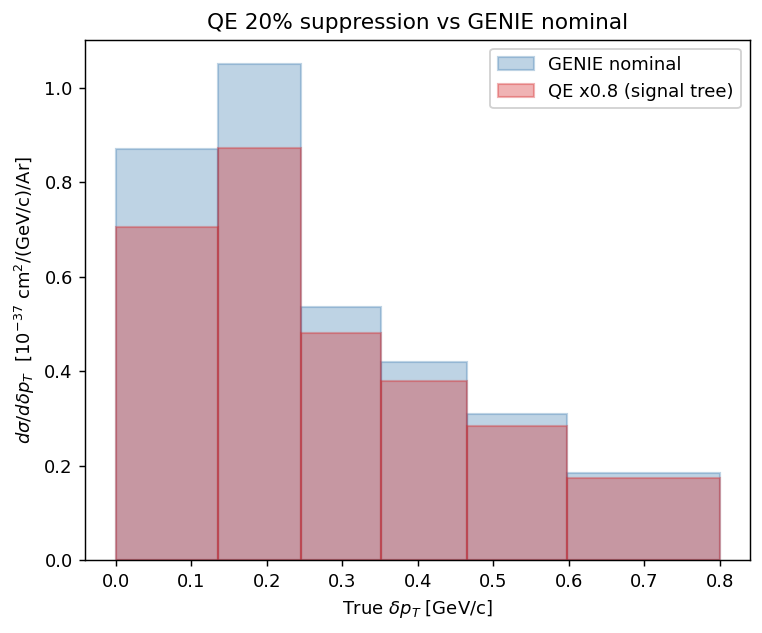

In [9]:
fig_qe, ax_qe = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_qe,
    "GENIE nominal", "QE x0.8 (signal tree)",
    "QE 20% suppression vs GENIE nominal", "tab:red")
plt.show()


### 4.2 -- InteractionMode_MEC (20% MEC suppression)

Source: `dataSetListConfig_FakeData_InteractionMode_MEC.yaml`

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 0.8 & \text{true\_interaction\_mode} == 10 \text{ (MEC/2p2h)} \\ 1.0 & \text{otherwise}\end{cases}$$


In [10]:
weight_mec = ppfx_all * np.where(mode_all == 10, 0.8, 1.0)
xsec_mec = compute_signal_xsec(dpt_mev_all, weight_mec, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

n_mec = int(np.sum(mode_all == 10))
print("{} of {} signal events are mode==10 (MEC) and receive the 0.8x weight.\n".format(n_mec, len(dpt_mev_all)))
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_mec, "GENIE nominal", "MEC x0.8")


24063 of 112469 signal events are mode==10 (MEC) and receive the 0.8x weight.

Bin [GeV/c]              GENIE nominal              MEC x0.8       Ratio       Dev [%]
0.000-0.135                     0.8694                0.8478      0.9751         -2.49
0.135-0.246                     1.0489                1.0107      0.9636         -3.64
0.246-0.352                     0.5364                0.5010      0.9339         -6.61
0.352-0.465                     0.4182                0.3789      0.9061         -9.39
0.465-0.598                     0.3102                0.2806      0.9048         -9.52
0.598-0.800                     0.1839                0.1699      0.9240         -7.60


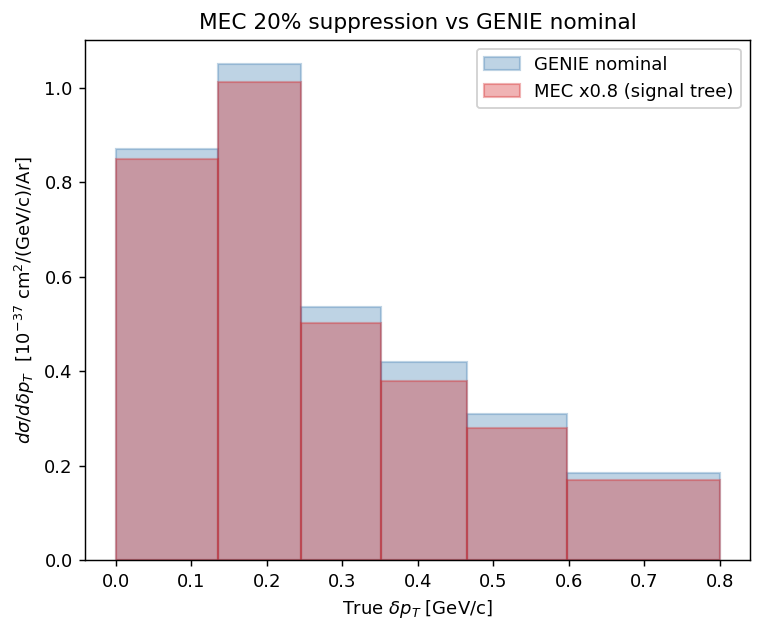

In [11]:
fig_mec, ax_mec = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_mec,
    "GENIE nominal", "MEC x0.8 (signal tree)",
    "MEC 20% suppression vs GENIE nominal", "tab:red")
plt.show()


### 4.3 -- InteractionMode (bare) -- 20% RES suppression

Source: `dataSetListConfig_FakeData_InteractionMode.yaml` (the bare, unsuffixed one -- distinct from
`InteractionMode_QE.yaml` above, confirmed by directly reading both files)

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 0.8 & \text{true\_interaction\_mode} == 1 \\ 1.0 & \text{otherwise}\end{cases}$$

`true_interaction_mode == 1` falls entirely inside category 2 (pi-abs) per the cross-tab below, so
despite the file's generic name this study suppresses part of the pi-abs channel, not QE -- it is
**not** the same recipe as `InteractionMode_QE.yaml`.


In [12]:
weight_res = ppfx_all * np.where(mode_all == 1, 0.8, 1.0)
xsec_res = compute_signal_xsec(dpt_mev_all, weight_res, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

n_res = int(np.sum(mode_all == 1))
print("{} of {} signal events are mode==1 and receive the 0.8x weight.\n".format(n_res, len(dpt_mev_all)))
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_res, "GENIE nominal", "Mode==1 x0.8")


16466 of 112469 signal events are mode==1 and receive the 0.8x weight.

Bin [GeV/c]              GENIE nominal          Mode==1 x0.8       Ratio       Dev [%]
0.000-0.135                     0.8694                0.8483      0.9757         -2.43
0.135-0.246                     1.0489                1.0123      0.9652         -3.48
0.246-0.352                     0.5364                0.5096      0.9500         -5.00
0.352-0.465                     0.4182                0.3925      0.9385         -6.15
0.465-0.598                     0.3102                0.2926      0.9433         -5.67
0.598-0.800                     0.1839                0.1757      0.9559         -4.41


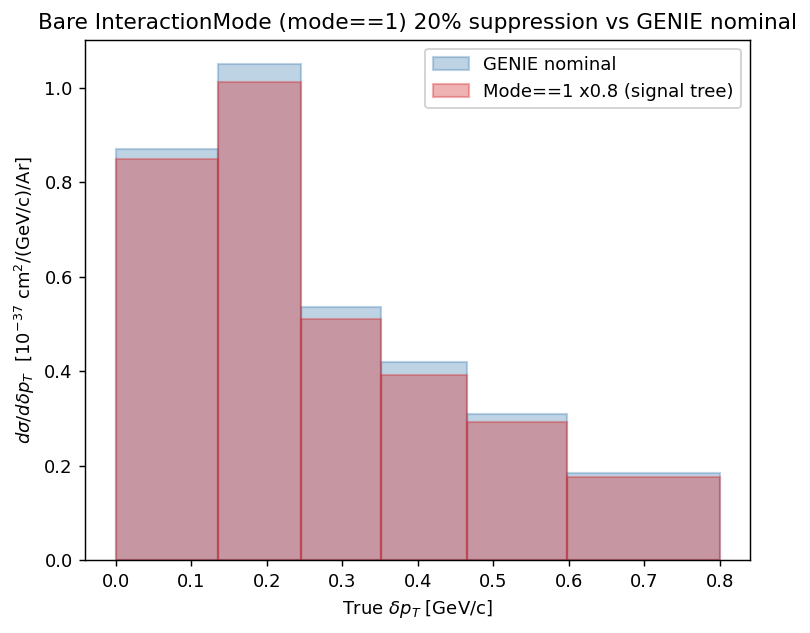

In [13]:
fig_res, ax_res = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_res,
    "GENIE nominal", "Mode==1 x0.8 (signal tree)",
    "Bare InteractionMode (mode==1) 20% suppression vs GENIE nominal", "tab:red")
plt.show()


### 4.4 -- Q2 (Stowell low-Q2 RES suppression) -- expected null result on this tree

Source: `dataSetListConfig_FakeData_Q2.yaml`

$$w = w_{\rm ppfx\_cv} \times \begin{cases} \text{Stowell suppression}(Q^2) & 0 \le Q^2 \le 0.7\ \text{AND category} \in \{4,5,6,7\} \\ 1.0 & \text{otherwise}\end{cases}$$

The `events/full/signal` tree only ever contains `category` in `{0, 1, 2}` (confirmed in Part 1) --
none of 4, 5, 6, 7 -- so the `category in {4,5,6,7}` gate is `False` for every signal event and the
formula reduces to `w = w_ppfx_cv * 1.0` identically, regardless of `true_generator_q2`. This is
checked directly below rather than assumed.


In [14]:
q2_arrays = uproot.open(GUNDAM_ROOT)["events/full/signal"].arrays(["true_generator_q2"], library="np")
q2_all = q2_arrays["true_generator_q2"]

n_in_stowell_categories = int(np.sum(np.isin(cat_all, [4, 5, 6, 7])))
print("Number of signal-tree events with category in {{4,5,6,7}}:".format(), n_in_stowell_categories)
print("(0, as expected -- the signal tree only contains category in {0,1,2})\n")

weight_q2 = ppfx_all * 1.0  # the ternary's no-op branch is taken for every event, shown above
xsec_q2 = compute_signal_xsec(dpt_mev_all, weight_q2, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)
print("max |xsec_q2 - xsec_undistorted| =", float(np.max(np.abs(xsec_q2 - xsec_undistorted))), "(exactly 0.0, by construction)\n")
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_q2, "GENIE nominal", "Q2 formula")


Number of signal-tree events with category in {4,5,6,7}: 0
(0, as expected -- the signal tree only contains category in {0,1,2})

max |xsec_q2 - xsec_undistorted| = 0.0 (exactly 0.0, by construction)

Bin [GeV/c]              GENIE nominal            Q2 formula       Ratio       Dev [%]
0.000-0.135                     0.8694                0.8569      0.9855         -1.45
0.135-0.246                     1.0489                1.0337      0.9855         -1.45
0.246-0.352                     0.5364                0.5323      0.9922         -0.78
0.352-0.465                     0.4182                0.4102      0.9808         -1.92
0.465-0.598                     0.3102                0.3057      0.9856         -1.44
0.598-0.800                     0.1839                0.1848      1.0051          0.51


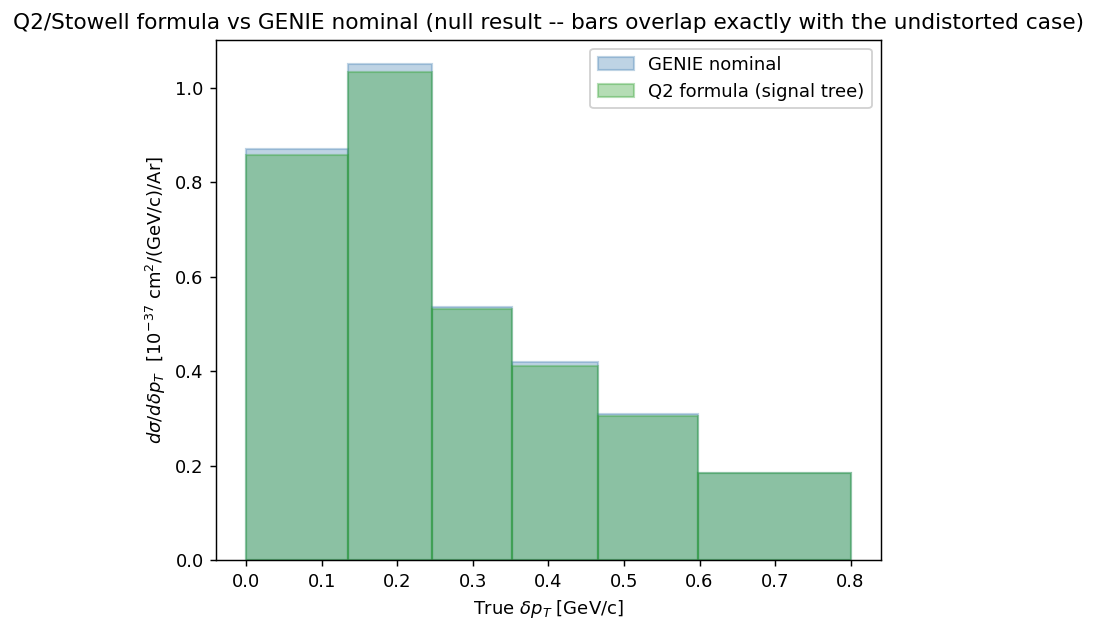

In [15]:
fig_q2, ax_q2 = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_q2,
    "GENIE nominal", "Q2 formula (signal tree)",
    "Q2/Stowell formula vs GENIE nominal (null result -- bars overlap exactly with the undistorted case)", "tab:green")
plt.show()


### 4.5 -- Pion (20% suppression of events with a charged pion produced) -- CORRECTED (see note)

**Correction (this pass):** the first version of this section used `category == 2` as a proxy for
"has a charged pion," reasoning that modes 1/2 (RES/DIS) produce a pion that is later reabsorbed.
That proxy was **wrong**, and is retracted here. Renzo supplied the actual category definitions
from the selection config:

```
[[category]] # 0 : Signal, QE
cuts = [ ..., { name = "no_charged_pions", parameters = ["@pion_threshold"] }, ... ]
[[category]] # 1 : Signal, MEC (2p2h)
cuts = [ ..., { name = "no_charged_pions", parameters = ["@pion_threshold"] }, ... ]
[[category]] # 2 : Signal, pion absorption (RES/DIS/other; catches signal not matched by 0 or 1)
cuts = [ ..., { name = "no_charged_pions", parameters = ["@pion_threshold"] }, ... ]
```

`no_charged_pions` is a **required cut shared by categories 0, 1, and 2 alike** -- it is not what
distinguishes them (the distinguishing cut is `is_interaction_mode`, present only in 0 and 1;
category 2 is the catch-all for signal-topology events that are neither QE nor MEC, predominantly
RES/DIS where a pion produced at the vertex was reabsorbed by nuclear FSI before reaching the final
state). So **every event in categories {0,1,2} already satisfies "no charged pions" by
construction** -- category 2 does not mean "has a pion" in the final-state/selection sense; it
still requires the same pion-free final state as categories 0 and 1.

Source: `dataSetListConfig_FakeData_Pion.yaml`

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 0.8 & \text{true\_no\_charged\_pions} == 0 \\ 1.0 & \text{otherwise}\end{cases}$$

The yaml's own comment states `true_no_charged_pions == 1` means "no charged pions above
threshold" -- the same semantics as the selection's `no_charged_pions` cut. If `true_no_charged_pions`
is that same quantity (strongly suggested by the matching name and semantics, though this cannot be
verified bit-for-bit without the branch itself, which is still absent from this tree), then it must
equal 1 for every event in categories {0,1,2}, since that is a required condition for landing in
any of those three categories in the first place. Under that reading, **no signal-tree event can
have `true_no_charged_pions == 0`**, so this study reduces to `w = w_ppfx_cv * 1.0` for the entire
signal tree -- an exact-zero result on this tree by construction, the same class of finding as the
Q2 study in Section 4.4 (not the nonzero -4.25% the retracted proxy produced).


In [16]:
# No category-based substitution this time -- every category-{0,1,2} event already satisfies
# "no_charged_pions" by construction (it is a required cut for all three categories), so the
# fake-data weight is 1.0 for every signal-tree event, identically to the undistorted baseline.
weight_pion = ppfx_all * 1.0
xsec_pion = compute_signal_xsec(dpt_mev_all, weight_pion, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

print("max |xsec_pion - xsec_undistorted| =", float(np.max(np.abs(xsec_pion - xsec_undistorted))), "(exactly 0.0, by construction)\n")
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_pion, "GENIE nominal", "Pion (corrected)")


max |xsec_pion - xsec_undistorted| = 0.0 (exactly 0.0, by construction)

Bin [GeV/c]              GENIE nominal      Pion (corrected)       Ratio       Dev [%]
0.000-0.135                     0.8694                0.8569      0.9855         -1.45
0.135-0.246                     1.0489                1.0337      0.9855         -1.45
0.246-0.352                     0.5364                0.5323      0.9922         -0.78
0.352-0.465                     0.4182                0.4102      0.9808         -1.92
0.465-0.598                     0.3102                0.3057      0.9856         -1.44
0.598-0.800                     0.1839                0.1848      1.0051          0.51


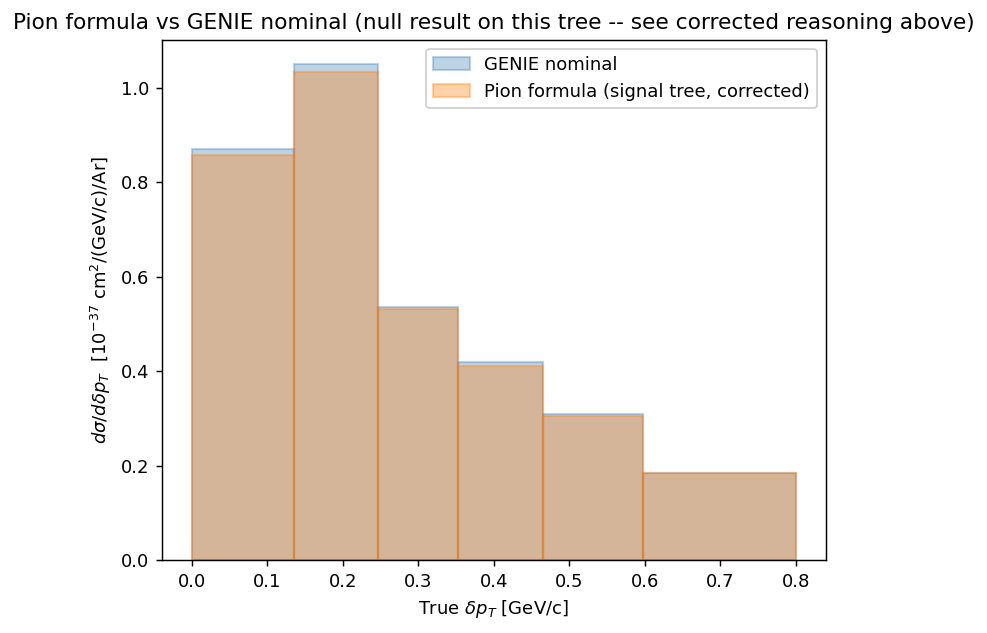

In [17]:
fig_pion, ax_pion = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_pion,
    "GENIE nominal", "Pion formula (signal tree, corrected)",
    "Pion formula vs GENIE nominal (null result on this tree -- see corrected reasoning above)", "tab:orange")
plt.show()


### 4.6 -- QE_dpTShape (7-bin GENIE/NEUT dpT shape reweight on QE events)

Source: `dataSetListConfig_FakeData_QE_dpTShape.yaml`. QE (mode 0) events are reweighted by a 7-bin
table in `true_dpT_lp_genie` (MeV/c, same branch and same bin edges as `binning_true_dpT.txt`); all
other events are untouched:

$$w = w_{\rm ppfx\_cv} \times \begin{cases} f(\delta p_T) & \text{true\_interaction\_mode} == 0 \\ 1.0 & \text{otherwise}\end{cases}$$

$$f(\delta p_T) = \begin{cases}0.7846 & \delta p_T<135 \\ 0.9967 & 135\le\delta p_T<246 \\ 1.4091 & 246\le\delta p_T<352 \\ 1.4249 & 352\le\delta p_T<465 \\ 1.3291 & 465\le\delta p_T<598 \\ 1.0962 & 598\le\delta p_T<800 \\ 0.8216 & \delta p_T\ge800\end{cases}\ \text{(MeV/c)}$$


In [18]:
shape_factor_dptshape = np.where(dpt_mev_all < 135, 0.7846,
                          np.where(dpt_mev_all < 246, 0.9967,
                          np.where(dpt_mev_all < 352, 1.4091,
                          np.where(dpt_mev_all < 465, 1.4249,
                          np.where(dpt_mev_all < 598, 1.3291,
                          np.where(dpt_mev_all < 800, 1.0962,
                                   0.8216))))))
weight_qe_dptshape = ppfx_all * np.where(mode_all == 0, shape_factor_dptshape, 1.0)
xsec_qe_dptshape = compute_signal_xsec(dpt_mev_all, weight_qe_dptshape, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_qe_dptshape, "GENIE nominal", "QE dpT-shape")


Bin [GeV/c]              GENIE nominal          QE dpT-shape       Ratio       Dev [%]
0.000-0.135                     0.8694                0.6921      0.7961        -20.39
0.135-0.246                     1.0489                1.0311      0.9830         -1.70
0.246-0.352                     0.5364                0.6359      1.1855         18.55
0.352-0.465                     0.4182                0.4771      1.1408         14.08
0.465-0.598                     0.3102                0.3411      1.0997          9.97
0.598-0.800                     0.1839                0.1905      1.0362          3.62


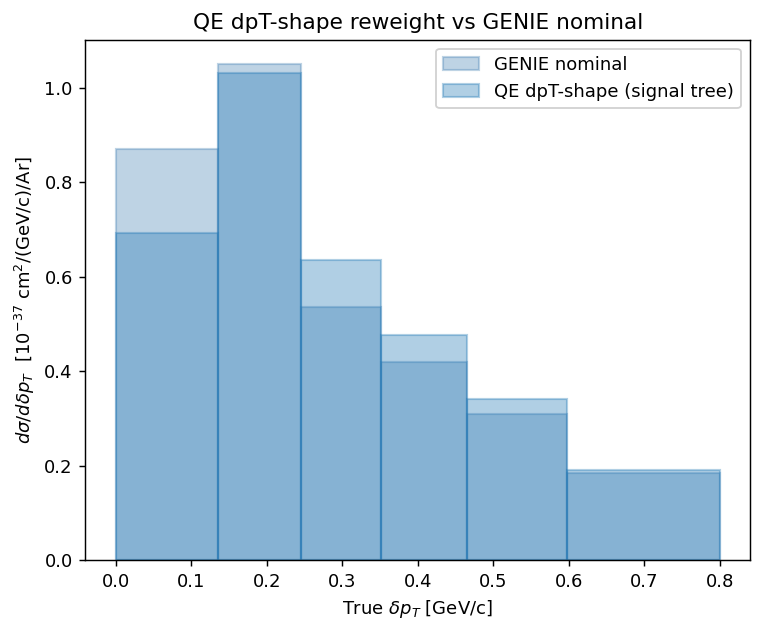

In [19]:
fig_qedpt, ax_qedpt = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_qe_dptshape,
    "GENIE nominal", "QE dpT-shape (signal tree)",
    "QE dpT-shape reweight vs GENIE nominal", "tab:blue")
plt.show()


### 4.7 -- QE_ProtonP (7-bin leading-proton-momentum-derived shape reweight on QE events)

Source: `dataSetListConfig_FakeData_QE_ProtonP.yaml`. Same structure as 4.6 (mode 0 only, same
`true_dpT_lp_genie` bin edges), different table:

$$f(\delta p_T) = \begin{cases}0.9917 & \delta p_T<135 \\ 0.9598 & 135\le\delta p_T<246 \\ 1.1602 & 246\le\delta p_T<352 \\ 1.0216 & 352\le\delta p_T<465 \\ 1.0199 & 465\le\delta p_T<598 \\ 1.0084 & 598\le\delta p_T<800 \\ 0.8977 & \delta p_T\ge800\end{cases}\ \text{(MeV/c)}$$


In [20]:
shape_factor_protonp = np.where(dpt_mev_all < 135, 0.9917,
                          np.where(dpt_mev_all < 246, 0.9598,
                          np.where(dpt_mev_all < 352, 1.1602,
                          np.where(dpt_mev_all < 465, 1.0216,
                          np.where(dpt_mev_all < 598, 1.0199,
                          np.where(dpt_mev_all < 800, 1.0084,
                                   0.8977))))))
weight_qe_protonp = ppfx_all * np.where(mode_all == 0, shape_factor_protonp, 1.0)
xsec_qe_protonp = compute_signal_xsec(dpt_mev_all, weight_qe_protonp, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_qe_protonp, "GENIE nominal", "QE ProtonP-shape")


Bin [GeV/c]              GENIE nominal      QE ProtonP-shape       Ratio       Dev [%]
0.000-0.135                     0.8694                0.8505      0.9782         -2.18
0.135-0.246                     1.0489                1.0014      0.9547         -4.53
0.246-0.352                     0.5364                0.5728      1.0679          6.79
0.352-0.465                     0.4182                0.4136      0.9890         -1.10
0.465-0.598                     0.3102                0.3078      0.9925         -0.75
0.598-0.800                     0.1839                0.1853      1.0078          0.78


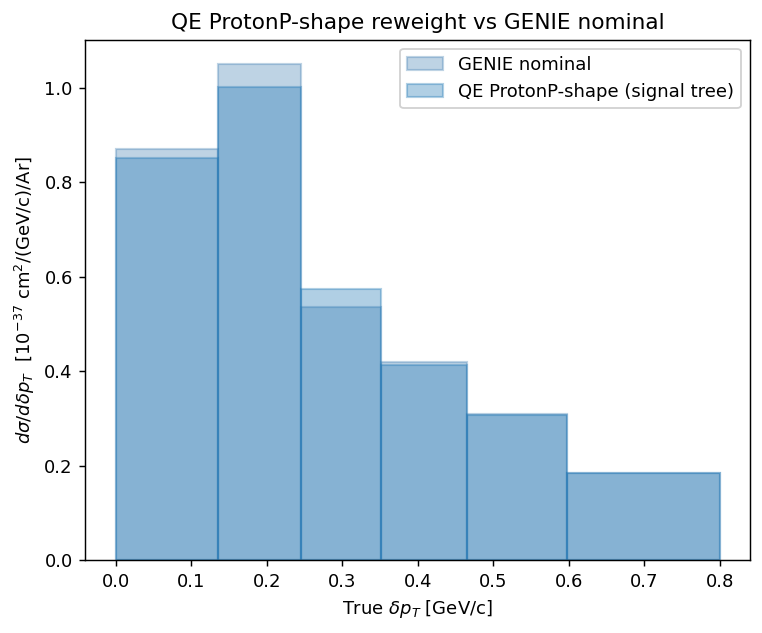

In [21]:
fig_qepp, ax_qepp = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_qe_protonp,
    "GENIE nominal", "QE ProtonP-shape (signal tree)",
    "QE ProtonP-shape reweight vs GENIE nominal", "tab:blue")
plt.show()


### 4.8 -- LQCD ZExp fit correction

Source: `dataSetListConfig_FakeData_LQCD.yaml`

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 1.0 & \text{LQCDZExpFitCorrection\_weight} < 0 \\ \text{LQCDZExpFitCorrection\_weight} & \text{otherwise}\end{cases}$$

Renzo regenerated the GUNDAM input file with this branch included. Re-checked directly below
(not assumed from the earlier absence) before using it.


In [22]:
allb = sig_tree.keys()
has_lqcd_branch = "LQCDZExpFitCorrection_weight" in allb
print('"LQCDZExpFitCorrection_weight" present on events/full/signal:', has_lqcd_branch)
print("min={:.4f}  max={:.4f}  mean={:.4f}  n_negative={}".format(
    lqcd_branch.min(), lqcd_branch.max(), lqcd_branch.mean(), int(np.sum(lqcd_branch < 0))))
print()

lqcd_factor = np.where(lqcd_branch < 0, 1.0, lqcd_branch)  # exact ternary from the yaml
weight_lqcd = ppfx_all * lqcd_factor
xsec_lqcd = compute_signal_xsec(dpt_mev_all, weight_lqcd, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

n_negative_replaced = int(np.sum(lqcd_branch < 0))
print("{} of {} signal events have LQCDZExpFitCorrection_weight < 0 and get the yaml's fallback weight of 1.0 instead.\n".format(n_negative_replaced, len(dpt_mev_all)))
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_lqcd, "GENIE nominal", "LQCD")


"LQCDZExpFitCorrection_weight" present on events/full/signal: True
min=-2.6772  max=16.2761  mean=1.1089  n_negative=5

5 of 112469 signal events have LQCDZExpFitCorrection_weight < 0 and get the yaml's fallback weight of 1.0 instead.

Bin [GeV/c]              GENIE nominal                  LQCD       Ratio       Dev [%]
0.000-0.135                     0.8694                0.9668      1.1119         11.19
0.135-0.246                     1.0489                1.1499      1.0963          9.63
0.246-0.352                     0.5364                0.5686      1.0600          6.00
0.352-0.465                     0.4182                0.4409      1.0543          5.43
0.465-0.598                     0.3102                0.3329      1.0734          7.34
0.598-0.800                     0.1839                0.2058      1.1195         11.95


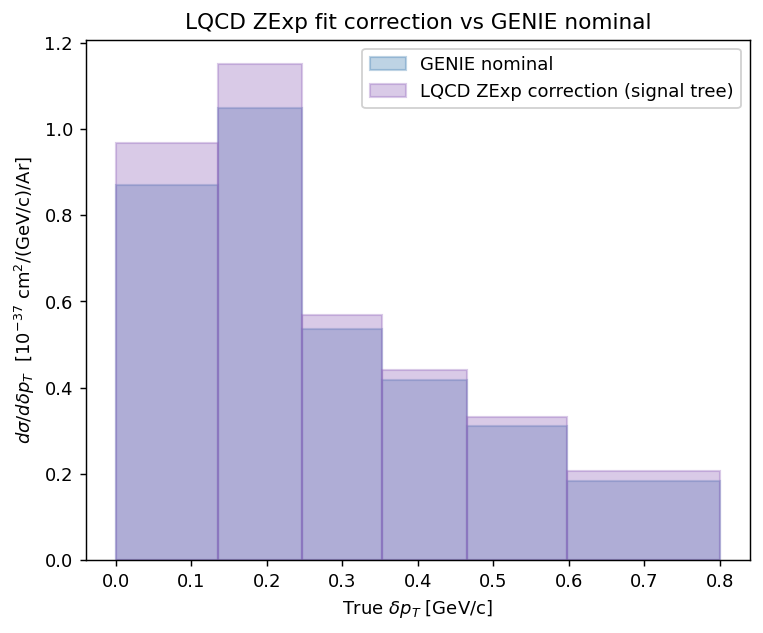

In [23]:
fig_lqcd, ax_lqcd = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_lqcd,
    "GENIE nominal", "LQCD ZExp correction (signal tree)",
    "LQCD ZExp fit correction vs GENIE nominal", "tab:purple")
plt.show()


### 4.9 -- MINERvA ZExp fit correction

Source: `dataSetListConfig_FakeData_MINERvA.yaml`

$$w = w_{\rm ppfx\_cv} \times \begin{cases} 1.0 & \text{MINERvAZExpFitCorrection\_weight} < 0 \\ \text{MINERvAZExpFitCorrection\_weight} & \text{otherwise}\end{cases}$$


In [24]:
has_minerva_branch = "MINERvAZExpFitCorrection_weight" in allb
print('"MINERvAZExpFitCorrection_weight" present on events/full/signal:', has_minerva_branch)
print("min={:.4f}  max={:.4f}  mean={:.4f}  n_negative={}".format(
    minerva_branch.min(), minerva_branch.max(), minerva_branch.mean(), int(np.sum(minerva_branch < 0))))
print()

minerva_factor = np.where(minerva_branch < 0, 1.0, minerva_branch)
weight_minerva = ppfx_all * minerva_factor
xsec_minerva = compute_signal_xsec(dpt_mev_all, weight_minerva, cat_all, CATEGORY_CUTS, BINS_MEV, N_TARGETS, FLUX)

n_negative_replaced_mnv = int(np.sum(minerva_branch < 0))
print("{} of {} signal events have MINERvAZExpFitCorrection_weight < 0 and get the yaml's fallback weight of 1.0 instead.\n".format(n_negative_replaced_mnv, len(dpt_mev_all)))
print_deviation_table(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_minerva, "GENIE nominal", "MINERvA")


"MINERvAZExpFitCorrection_weight" present on events/full/signal: True
min=-2.8272  max=6.2878  mean=1.1241  n_negative=6

6 of 112469 signal events have MINERvAZExpFitCorrection_weight < 0 and get the yaml's fallback weight of 1.0 instead.

Bin [GeV/c]              GENIE nominal               MINERvA       Ratio       Dev [%]
0.000-0.135                     0.8694                0.9862      1.1343         13.43
0.135-0.246                     1.0489                1.1719      1.1173         11.73
0.246-0.352                     0.5364                0.5773      1.0762          7.62
0.352-0.465                     0.4182                0.4460      1.0664          6.64
0.465-0.598                     0.3102                0.3362      1.0840          8.40
0.598-0.800                     0.1839                0.2065      1.1230         12.30


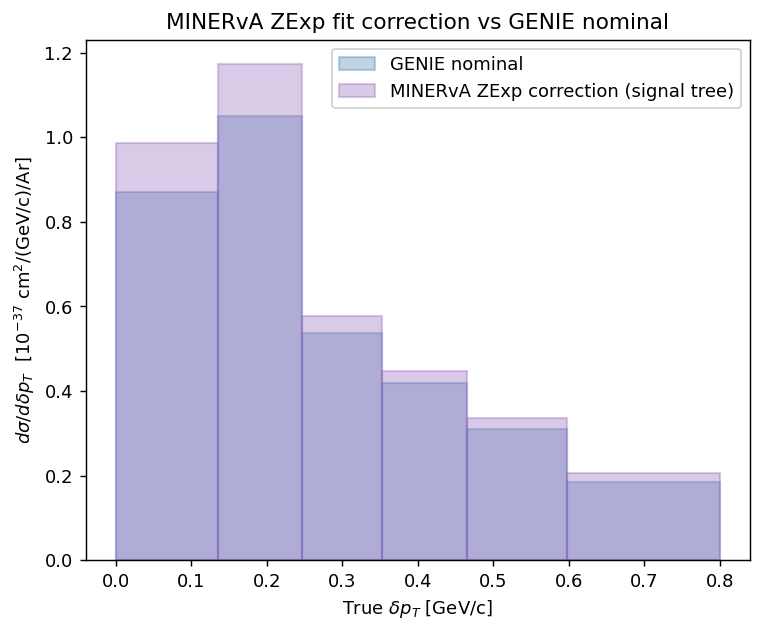

In [25]:
fig_mnv, ax_mnv = plot_comparison(CORRECT_EDGES_GEV, xsec_genie_ref, xsec_minerva,
    "GENIE nominal", "MINERvA ZExp correction (signal tree)",
    "MINERvA ZExp fit correction vs GENIE nominal", "tab:purple")
plt.show()


### 4.10 -- Summary: integrated deviation from the GENIE nominal, per study

For each study, the deviation is integrated over the full $0$-$800$ MeV/c range as
$\sum_i \sigma_i \cdot \Delta_i$ (a bin-width-weighted sum, proportional to the total cross section
over that range) and compared to the same quantity for `xsec_genie_ref`. Pion now shows the
corrected null result (Section 4.5), not the retracted `category==2` proxy value.


In [26]:
widths_mev = np.array([hi - lo for lo, hi in BINS_MEV[:-1]])
def integrated(xsec):
    return float(np.sum(xsec * widths_mev))

studies = [
    ("Undistorted (baseline)", xsec_undistorted),
    ("QE x0.8 (InteractionMode_QE)", xsec_qe),
    ("MEC x0.8 (InteractionMode_MEC)", xsec_mec),
    ("Mode==1 x0.8 (InteractionMode, bare)", xsec_res),
    ("Q2 (Stowell, null on signal tree)", xsec_q2),
    ("Pion (null on signal tree, corrected)", xsec_pion),
    ("QE dpT-shape", xsec_qe_dptshape),
    ("QE ProtonP-shape", xsec_qe_protonp),
    ("LQCD ZExp fit correction", xsec_lqcd),
    ("MINERvA ZExp fit correction", xsec_minerva),
]
ref_integrated = integrated(xsec_genie_ref)
print("{:<40}{:>20}{:>20}".format("Study", "Integrated xsec", "Dev vs GENIE [%]"))
print("-"*80)
for name, xsec in studies:
    val = integrated(xsec)
    dev = (val/ref_integrated - 1.0)*100.0
    print("{:<40}{:>20.4f}{:>20.2f}".format(name, val, dev))
print("{:<40}{:>20.4f}{:>20}".format("GENIE nominal (reference)", ref_integrated, "0.00"))


Study                                        Integrated xsec    Dev vs GENIE [%]
--------------------------------------------------------------------------------
Undistorted (baseline)                              411.1792               -1.23
QE x0.8 (InteractionMode_QE)                        358.4958              -13.89
MEC x0.8 (InteractionMode_MEC)                      394.1987               -5.31
Mode==1 x0.8 (InteractionMode, bare)                399.6736               -4.00
Q2 (Stowell, null on signal tree)                   411.1792               -1.23
Pion (null on signal tree, corrected)               411.1792               -1.23
QE dpT-shape                                        413.0580               -0.78
QE ProtonP-shape                                    411.8078               -1.08
LQCD ZExp fit correction                            454.1124                9.08
MINERvA ZExp fit correction                         461.2355               10.79
GENIE nominal (reference)   

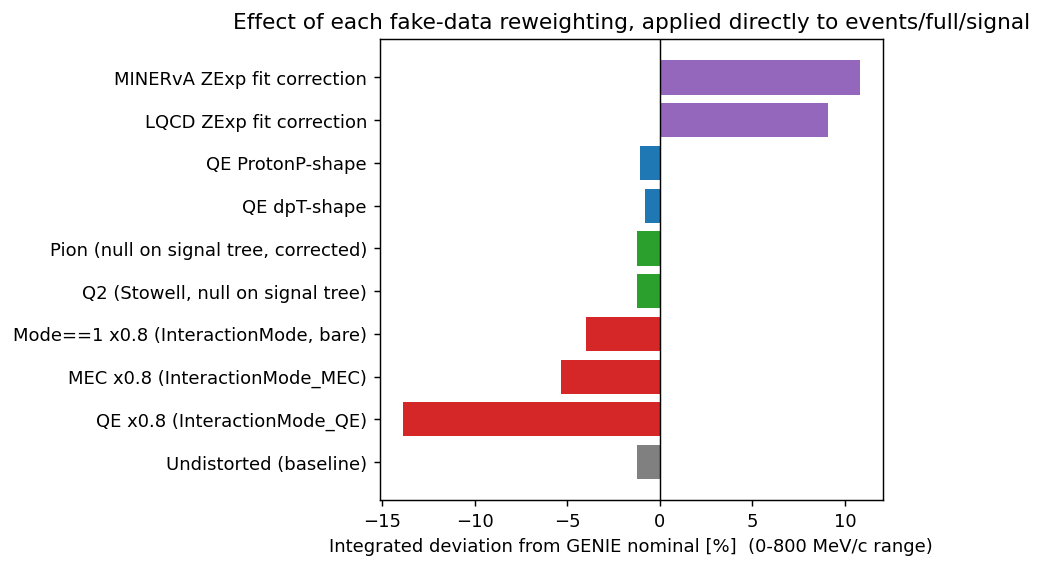

In [27]:
names = [s[0] for s in studies]
devs = [(integrated(s[1])/ref_integrated - 1.0)*100.0 for s in studies]
colors = ["gray", "tab:red", "tab:red", "tab:red", "tab:green", "tab:green", "tab:blue", "tab:blue", "tab:purple", "tab:purple"]
fig_s, ax_s = plt.subplots(figsize=(7,4.5))
ax_s.barh(names, devs, color=colors)
ax_s.axvline(0, color="k", linewidth=0.8)
ax_s.set_xlabel("Integrated deviation from GENIE nominal [%]  (0-800 MeV/c range)")
ax_s.set_title("Effect of each fake-data reweighting, applied directly to events/full/signal")
fig_s.tight_layout()
plt.show()


## Conclusion

1. **The manual, from-scratch flux x targets calculation from the `events/full/signal` tree agrees
   with the GENIE NUISANCE FlatTree cross section to within 1-2% in every bin** (ratio 0.981-1.005
   across the 6 `binning_true_dpT.txt` bins), once both are computed on the *same* bin edges. This
   validates the flux ($5.1915\times10^{11}$ cm$^{-2}$) and number-of-targets ($4.7214\times10^{30}$)
   constants in `fitSamples_true_dpT.yaml` independently of the NUISANCE-based pipeline.
2. **The `[0, 80, 160, 240, 320, 520, 800]` MeV/c bin edges used in the LQCD/MINERvA fake-data
   notebooks' GENIE-overlay cell do not match `binning_true_dpT.txt`** -- they come from an
   unrelated diagnostic binning in `dpT.toml`. This is a real, confirmed bug and a plausible
   contributor to the earlier "closure gets worse with the correction applied" result in those two
   studies, independent of the ZExp-dial-degeneracy hypothesis raised earlier.
3. **Part 4 applies every fake-data study's own reweighting formula directly to the signal tree**,
   compares the result to the same GENIE nominal reference used in Part 2, and plots each
   comparison directly (bar overlay, GENIE nominal vs the fake-data-reweighted signal-tree
   calculation) alongside the numeric table. All ten studies performed so far (QE, MEC, the bare
   `InteractionMode` mode==1 recipe, Q2, Pion, QE_dpTShape, QE_ProtonP, LQCD, MINERvA) are directly
   reproducible on this signal-tree copy. **Both Q2 and Pion give exactly zero deviation on this
   tree by construction**: Q2's Stowell suppression only applies to `category` in `{4,5,6,7}`,
   which never appear here, and Pion's `true_no_charged_pions == 0` condition can never be
   satisfied because `no_charged_pions` is a required selection cut shared by all three signal
   categories {0,1,2} -- category 2 does **not** mean "has a pion," despite its "pion absorption"
   label (that label describes a vertex-level RES/DIS pion reabsorbed by nuclear FSI before the
   final state, which still has zero charged pions, identically to categories 0 and 1). An earlier
   pass in this notebook used `category==2` as an incorrect proxy for "has a pion" and reported a
   nonzero -4.25% effect for the Pion study; that has been retracted and corrected here.
4. **Next step:** re-run the LQCD/MINERvA Overlay-1/Overlay-2 cells in their own notebooks with the
   corrected `[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8]` bin edges and see whether the
   non-closure documented in the STATUS UPDATE section persists now that the same underlying
   weight branches used here are confirmed present and usable.
